In [2]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv('l-37-house.csv', usecols=['GarageQual','FireplaceQu','SalePrice'])

In [4]:
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [5]:
# regression problem -- traget ==> numerical col , predict price


In [6]:
df.isnull().mean()

FireplaceQu    0.472603
GarageQual     0.055479
SalePrice      0.000000
dtype: float64

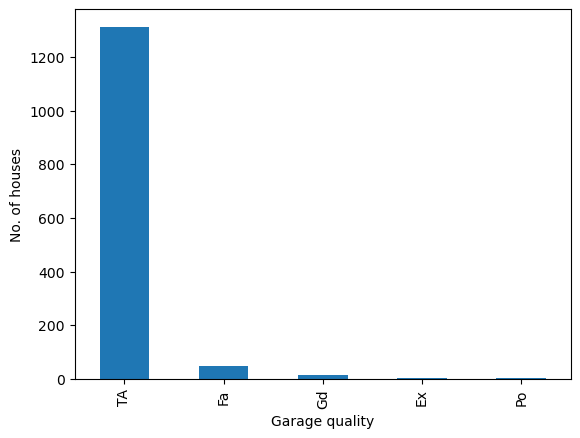

In [7]:
df['GarageQual'].value_counts().plot(kind='bar')
plt.xlabel('Garage quality')
plt.ylabel('No. of houses')
plt.show()


# now we will imputer with new values -->"Missing" ==>this will create a new Category 

In [8]:
df['GarageQual'].fillna('Missing', inplace=True)

/var/folders/jd/5681g6rx58xgpr8txbqb17p80000gn/T/ipykernel_37574/4070582888.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['GarageQual'].fillna('Missing', inplace=True)


Text(0, 0.5, 'Number of houses')

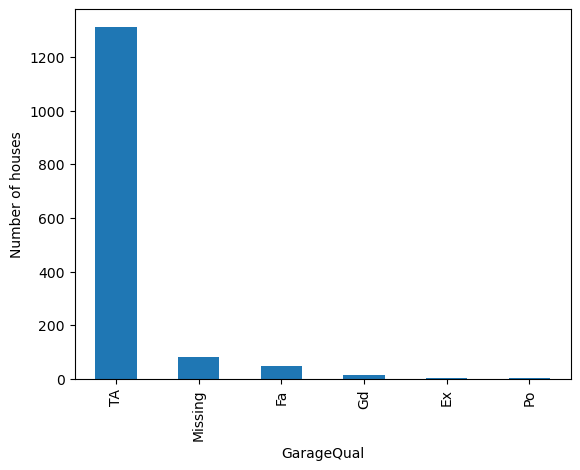

In [9]:
df['GarageQual'].value_counts().sort_values(ascending=False).plot.bar()
plt.xlabel('GarageQual')
plt.ylabel('Number of houses')

## this missing -- strategy will best work on the FireplaceQu col --> since it has 47% missing values

In [10]:
# we will now the same with sklearn

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['SalePrice']),df['SalePrice'],test_size=0.2)



from sklearn.impute import SimpleImputer



imputer = SimpleImputer(strategy='constant',fill_value='Missing')



X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_train)



imputer.statistics_

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


array(['Missing', 'Missing'], dtype=object)